# Importing and loading stuff

In [94]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import skellam
import shap
import statsmodels.api as sm
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import log_loss, mean_absolute_error, root_mean_squared_error, accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

In [2]:
SEED = 42

In [3]:
euro_test_path: str = "../data/EuroTest.csv"
euro_training_path: str = "../data/EuroTraining.csv"

In [4]:
euro_test_df: pd.DataFrame = pd.read_csv(euro_test_path)
euro_training_df: pd.DataFrame = pd.read_csv(euro_training_path)

In [5]:
euro_features: list[str] = [
    "GroupStage",
    "GDP",
    "MarketValue", 
    "FifaRank", 
    "UefaPoints",
    "CLPlayers",
    "Year"
]
euro_feat_df: pd.DataFrame = euro_training_df[euro_features]
euro_feat_test_df: pd.DataFrame = euro_test_df[euro_features]

In [6]:
response_var: str = "Goals"

response_train: pd.Series = euro_training_df[response_var]
response_test: pd.Series = euro_test_df[response_var]

# Inspection of the Data

### Dimensions and Features

In [7]:
euro_feat_df.shape

(390, 7)

In [8]:
euro_feat_test_df.shape

(102, 7)

In [9]:
euro_feat_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 390 entries, 0 to 389
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   GroupStage   390 non-null    int64  
 1   GDP          390 non-null    float64
 2   MarketValue  390 non-null    float64
 3   FifaRank     390 non-null    int64  
 4   UefaPoints   390 non-null    int64  
 5   CLPlayers    390 non-null    float64
 6   Year         390 non-null    int64  
dtypes: float64(3), int64(4)
memory usage: 21.5 KB


In [10]:
euro_feat_test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   GroupStage   102 non-null    int64  
 1   GDP          102 non-null    float64
 2   MarketValue  102 non-null    float64
 3   FifaRank     102 non-null    int64  
 4   UefaPoints   102 non-null    int64  
 5   CLPlayers    102 non-null    float64
 6   Year         102 non-null    int64  
dtypes: float64(3), int64(4)
memory usage: 5.7 KB


In [11]:
euro_feat_df.describe()

,GroupStage,GDP,MarketValue,FifaRank,UefaPoints,CLPlayers,Year
count,390.000000,390.000000,390.000000,390.000000,390.000000,390.000000,390.000000
mean,0.738462,0.000000,0.000000,0.000000,0.000000,0.000000,2013.230769
std,0.440037,1.111590,1.184666,22.643317,37148.938831,4.001733,5.675281
min,0.000000,-2.967327,-2.823777,-96.000000,-100263.000000,-14.000000,2004.000000
25%,0.000000,-0.659215,-0.911463,-13.000000,-25177.750000,-1.769231,2008.000000
50%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2016.000000
75%,1.000000,0.659215,0.911463,13.000000,25177.750000,1.769231,2020.000000
max,1.000000,2.967327,2.823777,96.000000,100263.000000,14.000000,2020.000000


In [12]:
euro_training_df.groupby("Year").size()

Year
2004     62
2008     62
2012     62
2016    102
2020    102
dtype: int64

### Missing Values

In [13]:
euro_feat_df.isna().sum()

GroupStage     0
GDP            0
MarketValue    0
FifaRank       0
UefaPoints     0
CLPlayers      0
Year           0
dtype: int64

### duplicates

In [14]:
euro_feat_df.duplicated().sum()

np.int64(0)

# Models

## Creating K-fold

In [15]:
years = np.sort(euro_feat_df["Year"].unique())
tscv = TimeSeriesSplit(n_splits=3)
cv = [
    (
        np.flatnonzero(euro_feat_df["Year"].isin(years[k])),
        np.flatnonzero(euro_feat_df["Year"].isin(years[v])),
    )
    for k, v in tscv.split(years)
]


In [16]:
euro_feat_df = euro_feat_df.drop("Year", axis=1)
euro_feat_test_df = euro_feat_test_df.drop("Year", axis=1)

## Poisson 

### Poisson with sklearn and tuning

In [36]:
pipe_poireg = make_pipeline(
    StandardScaler(),
    PoissonRegressor(max_iter=2000)
)
params_poireg = {
    "poissonregressor__alpha": np.logspace(-4, 2, 15)
}
## what about standardscaler
grid_poireg = GridSearchCV(
    estimator=pipe_poireg,
    param_grid=params_poireg,
    scoring="neg_mean_poisson_deviance", Cross-Validation-MAE und RMSE bewerten, anschließend die Permutation Importance darstellen und danach für die zwei oder drei wichtigsten Features PDPs oder ALE-Plots erstellen.

Damit beantwortest du drei unterschiedliche Fragen: Wie gut prognostiziert der Random Forest? Welche Variablen sind wichtig? Und wie hängen diese Variablen mit den vorhergesagten Toren zusammen?
    cv=cv
)
grid_poireg.fit(euro_feat_df, response_train)

euro_test_predictions = grid_poireg.predict(euro_feat_test_df)

### Inspection of Poisson model

In [37]:
# calculate error with test set
# TODO change the train test splitting
mae_euro_poisson = mean_absolute_error(response_test, euro_test_predictions)
rmse_euro_poisson = root_mean_squared_error(response_test, euro_test_predictions)
print("Poisson regressor\nMAE\tRMSE")
print(*map(lambda x: round(x, 2), (mae_euro_poisson, rmse_euro_poisson)), sep="\t")

Poisson regressor
MAE	RMSE
0.74	0.96


In [38]:
grid_poireg.best_params_

{'poissonregressor__alpha': np.float64(0.2682695795279725)}

In [44]:
sk_poi_model = grid_poireg.best_estimator_.named_steps["poissonregressor"]
coefs = pd.Series(
    sk_poi_model.coef_,
    index=euro_feat_df.columns, 
    name="Coefficient"
)
print(coefs.sort_values())
print("Intercept:", sk_poi_model.intercept_)

FifaRank      -0.071219
GroupStage    -0.016692
UefaPoints     0.029836
CLPlayers      0.087990
GDP            0.099840
MarketValue    0.133855
Name: Coefficient, dtype: float64
Intercept: 0.13472022014470905


In [46]:
coefs_meaning = np.expm1(coefs) * 100
coefs_meaning.sort_values()

FifaRank       -6.874210
GroupStage     -1.655319
UefaPoints      3.028531
CLPlayers       9.197729
GDP            10.499383
MarketValue    14.322688
Name: Coefficient, dtype: float64

### Poisson with statsmodels

In [41]:
train_sm_poi = sm.add_constant(euro_feat_df)

sm_poi = sm.GLM(
    response_train,
    train_sm_poi,
    family=sm.families.Poisson()
)
result = sm_poi.fit()
print(result.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  Goals   No. Observations:                  390
Model:                            GLM   Df Residuals:                      383
Model Family:                 Poisson   Df Model:                            6
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -527.27
Date:                Wed, 11 Nov 2026   Deviance:                       412.89
Time:                        09:58:21   Pearson chi2:                     352.
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1376
Covariance Type:            nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.1604      0.090      1.775      

In [50]:
sm_poi_test_df = sm.add_constant(euro_feat_test_df)
sm_poi_preds = result.predict(sm_poi_test_df)
mae_sm_poi = mean_absolute_error(response_test, sm_poi_preds)
rmse_sm_poi = root_mean_squared_error(response_test, sm_poi_preds)
print("Poisson regressor Statsmodel\nMAE\tRMSE")
print(*map(lambda x: round(x, 2), (mae_sm_poi, rmse_sm_poi)), sep="\t")

Poisson regressor Statsmodel
MAE	RMSE
0.74	0.96


We see that only GDP and Marketvalue are statisical significant.


## Random Forest

In [19]:
# TODO test different arguments for randomforest

params_rf: dict[str, list[float | int | None]] = {
    "n_estimators": [25, 50, 100],
    "max_depth": [2, 3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [1, 3, 5, 7],
}


grid_rf = GridSearchCV(
    estimator=RandomForestRegressor(n_jobs=-1, random_state=SEED),
    param_grid=params_rf,
    scoring="neg_mean_absolute_error",
    cv=cv,
    refit=True,
)

rf = grid_rf.fit(euro_feat_df, response_train)
rf_pred = rf.predict(euro_feat_test_df)

### Inspection of Random Forest

In [20]:
mae_euro_rf = mean_absolute_error(response_test, rf_pred)
rmse_euro_rf = root_mean_squared_error(response_test, rf_pred)
print("Random Forest Regressor\nMAE\tRMSE")
print(*map(lambda x: round(x, 2), (mae_euro_rf, rmse_euro_rf)), sep="\t")

Random Forest Regressor
MAE	RMSE
0.75	0.99


In [21]:
rf.best_params_

{'max_depth': 2,
 'min_samples_leaf': 3,
 'min_samples_split': 2,
 'n_estimators': 50}

### Feature Importance for forest TODO

In [54]:
perm_importance = permutation_importance(
    rf,
    euro_feat_test_df,
    response_test,
    scoring="neg_mean_squared_error",
    n_repeats=20,
    random_state=SEED,
    n_jobs=-1
)
importance_df: pd.DataFrame = pd.DataFrame(
    {
    "importances": perm_importance.importances_mean,
    "std": perm_importance.importances_std,
    },
    index= rf.feature_names_in_,
).sort_values("importances")

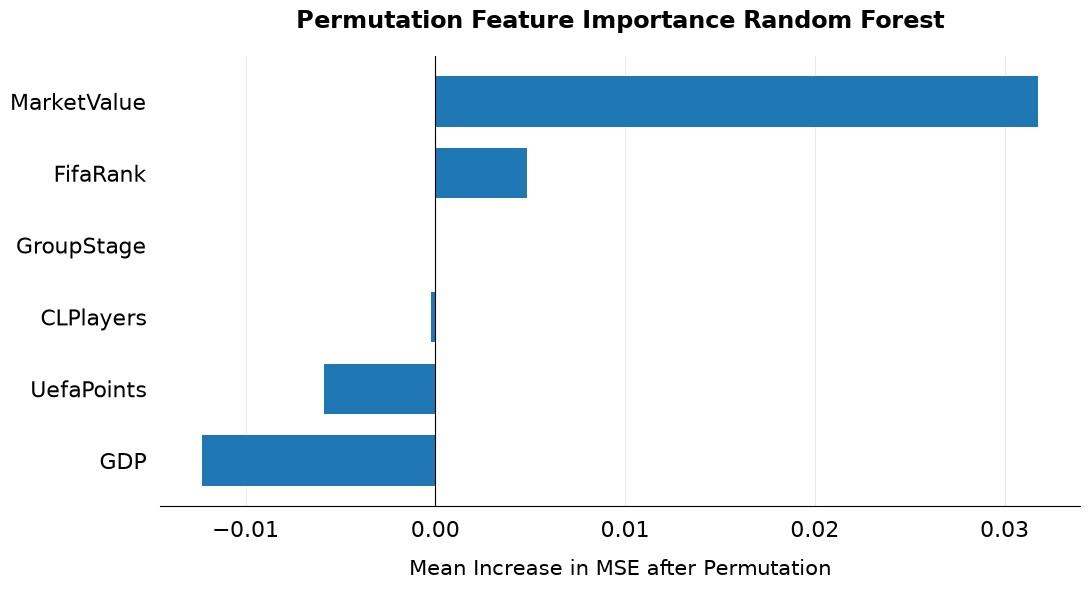

In [62]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    importance_df.index,
    importance_df["importances"],
    #xerr=importance_df["std"],
    capsize=4,
    height=0.7,
)

ax.set_title(
    "Permutation Feature Importance Random Forest",
    fontsize=17, 
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Mean Increase in MSE after Permutation",
    fontsize=15, 
    labelpad=12
)

ax.tick_params(
    labelsize=16, 
    pad=10, 
    length=0
)

ax.grid(axis="x", linestyle="-", alpha=.25) 
ax.set_axisbelow(True)

ax.axvline(0, color="black", linewidth=0.8)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

fig.tight_layout()

#   fig.savefig(
#       "../graphs/philipp_perm_graph_test.png", 
#       dpi=300,
#       bbox_inches="tight"
#   )
plt.show()

## XGBoost

In [22]:
# TODO train XGBoost tuning?
params_xgb = {
    "n_estimators": [25, 50, 100, 300],
    "max_depth": [3, 6, 9],
    "learning_rate": [0.01, 0.1, 0.2],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

grid_xgb = GridSearchCV(
    estimator=XGBRegressor(objective="count:poisson", random_state=SEED, n_jobs=1),
    param_grid=params_xgb,
    scoring="neg_mean_absolute_error",
    cv=cv,
    refit=True,
)

xgb = grid_xgb.fit(euro_feat_df, response_train)
xgb_pred = xgb.predict(euro_feat_test_df)

In [23]:
xgb.best_params_

{'colsample_bytree': 1.0,
 'learning_rate': 0.1,
 'max_depth': 3,
 'n_estimators': 50,
 'subsample': 0.8}

### Inspection of XGBoost

In [24]:
mae_euro_xgb = mean_absolute_error(response_test, xgb_pred)
rmse_euro_xgb = root_mean_squared_error(response_test, xgb_pred)
print("XGBoost Regressor\nMAE\tRMSE")
print(*map(lambda x: round(x, 2), (mae_euro_xgb, rmse_euro_xgb)), sep="\t")

XGBoost Regressor
MAE	RMSE
0.77	1.0


### Find a good metric for feature importance TODO

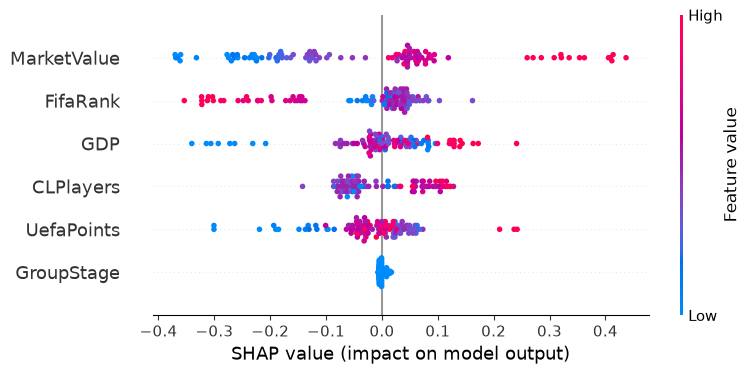

In [69]:
explain = shap.TreeExplainer(xgb.best_estimator_)
shap_vals = explain(euro_feat_test_df)
shap.plots.beeswarm(shap_vals, max_display=8)

## Neural Network

In [31]:

# TODO train neural_network tuning?
pipe = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(solver="lbfgs", max_iter=15000, random_state=SEED)),
    ]
)

params_nn = {
    "mlp__hidden_layer_sizes": [(4, 2), (5,), (10,), (20,), (10, 5)],
    "mlp__activation": ["relu", "tanh"],
    "mlp__alpha": [0.001, 0.01, 0.1],
}

grid_nn = GridSearchCV(
    estimator=pipe,
    param_grid=params_nn,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    refit=True,
)

nn = grid_nn.fit(euro_feat_df, response_train)
nn_pred = nn.predict(euro_feat_test_df)

### Inspection of Neural Network

In [32]:
mae_euro_nn = mean_absolute_error(response_test, nn_pred)
rmse_euro_nn = root_mean_squared_error(response_test, nn_pred)
print("Multi Layer Perceptron\nMAE\tRMSE")
print(*map(lambda x: round(x, 2), (mae_euro_nn, rmse_euro_nn)), sep="\t")

Multi Layer Perceptron
MAE	RMSE
0.81	1.05


In [33]:
nn.best_params_

{'mlp__activation': 'relu',
 'mlp__alpha': 0.01,
 'mlp__hidden_layer_sizes': (4, 2)}

## Model Comparison Graph

## Skellam for euro soccer TODO


In [70]:
mu_home = np.asarray(sm_poi_preds)[::2]
mu_away = np.asarray(sm_poi_preds)[1::2]

In [71]:
mu_home

array([1.94923168, 0.87774116, 1.52564945, 2.10249465, 0.76554768,
       0.82556585, 0.71455687, 0.96163474, 1.77545972, 0.71170858,
       1.55648034, 1.81980193, 1.82339085, 2.13083841, 0.95951887,
       1.08771299, 0.94145462, 1.3231212 , 1.083019  , 0.98787349,
       0.91839876, 0.91237947, 0.78036004, 1.99957065, 0.86501423,
       1.28331657, 0.58157497, 1.01810276, 1.51487164, 2.30110639,
       2.0815609 , 1.54671159, 1.32212548, 0.84138223, 0.58857001,
       1.13925538, 1.134654  , 1.5809026 , 2.069493  , 2.28153607,
       1.65548231, 1.98235234, 0.62473292, 1.36015015, 1.00869399,
       0.92408902, 1.47522825, 1.7551569 , 0.90042136, 1.11110718,
       1.08935756])

In [72]:
goal_home = np.asarray(response_test)[::2]
goal_away = np.asarray(response_test)[1::2]

In [87]:
probs = pd.DataFrame({
    "Loss": skellam.cdf(-1, mu_home, mu_away),
    "Draw": skellam.pmf(0, mu_home, mu_away),
    "Win": skellam.sf(0, mu_home, mu_away)
})
probs.head()

,Loss,Draw,Win
0,0.126680,0.205879,0.667441
1,0.536247,0.253585,0.210168
2,0.223167,0.258417,0.518416
3,0.103555,0.185966,0.710479
4,0.620245,0.225380,0.154375


In [77]:
real_outcomes = np.where(
    goal_home > goal_away, 2,
    np.where(
        goal_home == goal_away, 1, 
        0
    )
)
real_outcomes

array([2, 0, 2, 2, 0, 1, 0, 2, 0, 0, 2, 2, 1, 2, 1, 1, 1, 2, 0, 0, 1, 1,
       0, 2, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 2, 0, 2, 2, 2, 2, 2, 1, 0, 0,
       2, 1, 1, 2, 2, 0, 2])

### Skellam evaluation

In [79]:
p = probs.to_numpy()
one_hot_enc = np.eye(3)[real_outcomes]

In [81]:
ll = log_loss(real_outcomes, p, labels=[0,1,2])
ll

1.014035975838145

In [84]:
brier = np.mean(np.sum((p - one_hot_enc)**2, axis=1))
brier

np.float64(0.6106803180056053)

In [86]:
cumulative_preds = np.cumsum(p, axis=1)[:, :-1]
cumulative_reals = np.cumsum(one_hot_enc, axis=1)[:, :-1]
rank_prob_score = np.mean(np.sum((cumulative_preds - cumulative_reals)**2, axis=1) / 2) 
rank_prob_score

np.float64(0.19142401506090662)

In [92]:
predicted_outcome = np.argmax(probs.to_numpy(), axis = 1) 

### Accuracy score

In [93]:
acc = accuracy_score(real_outcomes, predicted_outcome) 
print("accuracy: ", acc)

accuracy:  0.47058823529411764


### Confusion matrix

In [97]:
cm = confusion_matrix(real_outcomes, predicted_outcome, labels=[0,1,2])

cm_df = pd.DataFrame(
    cm,
    index=["Acual Loss", "Actual Draw", "Actual Win"],
    columns=["Predicted Loss", "Predicted Draw", "Predicted Win"]
)
display(cm_df)

,Predicted Loss,Predicted Draw,Predicted Win
Acual Loss,11,0,4
Actual Draw,10,0,7
Actual Win,6,0,13


### Classification Report

In [98]:
print(classification_report(
    real_outcomes,
    predicted_outcome,
    labels=[0,1,2],
    target_names=["Loss", "Draw", "Win"],
    zero_division=0
))

              precision    recall  f1-score   support

        Loss       0.41      0.73      0.52        15
        Draw       0.00      0.00      0.00        17
         Win       0.54      0.68      0.60        19

    accuracy                           0.47        51
   macro avg       0.32      0.47      0.38        51
weighted avg       0.32      0.47      0.38        51

